# Product Development Analytics - Ulta Blush Shades
**Business context:** A product team deciding what to launch, what to cut, and who they compete with needs to see the shade market as a color space, not a list of names.

**Questions**
1. Where are the whitespace gaps?
2. How redundant are shades within a brand?
3. Which brands have a wide or narrow hue range per product line?
4. What should a new brand launch with?
5. Which brands compete head to head?

**Method backbone:** every shade is a point in CIELAB space (L* lightness, a*/b* color). ΔE (distance in LAB) measures how different two shades look: about 2.3 is just noticeable, under 5 is "same shade at a glance", over 10 is clearly different.
**Tools:** Python -> CSV exports -> Tableau dashboard.

## Setup & cleaning

In [1]:
import os, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.spatial import cKDTree
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=0.95)
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)
os.makedirs("tableau_exports", exist_ok=True)
MIN_N = 15          # minimum shades for a brand to be analyzed
SEASON_ORDER = ["light spring","bright/clear spring","true/warm spring",
                "light summer","soft summer","true/cool summer",
                "soft autumn","true/warm autumn","dark/deep autumn",
                "true/cool winter","bright/clear winter","dark/deep winter"]

In [3]:
# color science helpers (sRGB -> CIELAB, D65)
M = np.array([[0.4124564,0.3575761,0.1804375],[0.2126729,0.7151522,0.0721750],[0.0193339,0.1191920,0.9503041]])
WHITE = np.array([0.95047, 1.0, 1.08883])

def hex_to_rgb(h):
    h = h.lstrip("#"); return [int(h[i:i+2], 16) for i in (0, 2, 4)]

def rgb_to_lab(rgb):
    c = np.asarray(rgb, float) / 255
    c = np.where(c > 0.04045, ((c + 0.055) / 1.055) ** 2.4, c / 12.92)
    xyz = (c @ M.T) / WHITE
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16 / 116)
    return np.c_[116 * f[:, 1] - 16, 500 * (f[:, 0] - f[:, 1]), 200 * (f[:, 1] - f[:, 2])]

def lab_to_linear_rgb(lab):
    lab = np.asarray(lab, float)
    fy = (lab[:, 0] + 16) / 116
    f = np.c_[fy + lab[:, 1] / 500, fy, fy - lab[:, 2] / 200]
    xyz = np.where(f ** 3 > 0.008856, f ** 3, (f - 16 / 116) / 7.787) * WHITE
    return xyz @ np.linalg.inv(M).T

def lab_to_hex(lab):
    lin = np.clip(lab_to_linear_rgb(lab), 0, 1)
    c = np.where(lin > 0.0031308, 1.055 * lin ** (1 / 2.4) - 0.055, 12.92 * lin)
    return ["#%02x%02x%02x" % tuple(np.round(r * 255).astype(int)) for r in c]

def delta_e(a, b):
    """CIE76 delta-E: Euclidean distance in LAB. ~2.3 = just-noticeable difference."""
    return np.linalg.norm(np.asarray(a) - np.asarray(b), axis=-1)

In [4]:
DATA_FILE = "Ulta_Blush_HEX_Codes.csv" 
try:
    raw = pd.read_csv(DATA_FILE, encoding="utf-8-sig")   # utf-8-sig also strips a BOM if Excel added one
except UnicodeDecodeError:
    raw = pd.read_csv(DATA_FILE, encoding="cp1252") 
df = raw.rename(columns={"product url":"product_url","swatch alt":"swatch_alt","swatch image url":"swatch_img",
                         "dominant color 1":"hex","dominant color 2":"hex2","Season Type":"season"}).copy()
print("raw rows:", len(df))

# 1) recover missing product names from the product URL slug
slug = df.product_url.str.extract(r"/p/(.+?)-[a-zA-Z]*prod\d+")[0]
bad_name = df["name"].isna() | df["name"].astype(str).str.match(r"^(Err:|#ERROR|#N/A|#REF)")   # spreadsheet error cells
df["product"] = df["name"].where(~bad_name, slug.str.replace("-", " ").str.title())
print("product names still missing:", df["product"].isna().sum())

# 2) tidy text, drop exact duplicate swatches
df["brand"] = df["brand"].str.strip()
df["hex"] = df["hex"].str.lower().str.strip()
before = len(df)
df = df.drop_duplicates(subset=["brand", "swatch_alt", "hex"]).reset_index(drop=True)
print("duplicate swatches removed:", before - len(df))

# 3) dominant color 2 is mostly pure red (#fe0000 / #ff0000) -> extraction artifact, so only color 1 is used
print("share of hex2 that is near-pure red:", df.hex2.str.match(r"^#f[c-f]0[0-3]0[0-3]$").mean().round(2))
df = df.drop(columns=["hex2", "name"])

# 4) season family + LAB / LCh coordinates
df["family"] = df.season.str.extract(r"(spring|summer|autumn|winter)")[0]
df["season"] = pd.Categorical(df.season, SEASON_ORDER, ordered=True)
lab = rgb_to_lab([hex_to_rgb(h) for h in df.hex])
df[["L", "a", "b"]] = lab
df["C"] = np.hypot(df.a, df.b)                       # chroma
df["h"] = np.degrees(np.arctan2(df.b, df.a)) % 360   # hue angle
print("clean rows:", len(df), "| brands:", df.brand.nunique(), "| products:", df["product"].nunique())
df.head()

raw rows: 1405
product names still missing: 0
duplicate swatches removed: 119
share of hex2 that is near-pure red: 0.42
clean rows: 1286 | brands: 77 | products: 233


,product_url,shade,swatch_alt,brand,swatch_img,hex,season,product,family,L,a,b,C,h
0,https://www.ulta.com/p/cheek-freak-blush-balm-...,Big O,Big O Cheek Freak Blush Balm,about-face,https://media.ulta.com/i/ulta/2599828_sw?img40...,#842e39,dark/deep autumn,Cheek Freak Blush Balm,autumn,32.160294,37.777364,13.077085,39.976735,19.093906
1,https://www.ulta.com/p/cheek-freak-blush-balm-...,Champagne Room,Champagne Room Cheek Freak Blush Balm,about-face,https://media.ulta.com/i/ulta/2607795_sw?img40...,#f6586c,bright/clear spring,Cheek Freak Blush Balm,spring,59.581105,61.613274,22.206260,65.492850,19.819850
2,https://www.ulta.com/p/cheek-freak-blush-balm-...,Cowgirl,Cowgirl Cheek Freak Blush Balm,about-face,https://media.ulta.com/i/ulta/2599860_sw?img40...,#c0483d,bright/clear spring,Cheek Freak Blush Balm,spring,47.211762,47.468808,31.934036,57.210754,33.930192
3,https://www.ulta.com/p/cheek-freak-blush-balm-...,Get Some,Get Some Cheek Freak Blush Balm,about-face,https://media.ulta.com/i/ulta/2619149_sw?img40...,#a83f53,true/cool winter,Cheek Freak Blush Balm,winter,42.010482,44.794443,11.096037,46.148284,13.912694
4,https://www.ulta.com/p/cheek-freak-blush-balm-...,Laid,Laid Cheek Freak Blush Balm,about-face,https://media.ulta.com/i/ulta/2619150_sw?img40...,#fe708b,light summer,Cheek Freak Blush Balm,summer,65.380352,56.400153,12.551103,57.779819,12.545976


In [6]:
# Decision thresholds used throughout
DE_DUP   = 5    # two shades of one brand closer than this = redundant
DE_RIVAL = 6    # a rival's shade this close = effectively a substitute
DE_COVER = 8    # a launch shade "covers" market shades within this distance
GAP_DE   = 8    # an empty spot in color space farther than this from any shade = whitespace
brands_ok = df.brand.value_counts()[lambda s: s >= MIN_N].index.tolist()
print(len(brands_ok), "brands with >=", MIN_N, "shades")

37 brands with >= 15 shades


## 1. Where are the whitespace gaps?
**Method:** lay a fine grid over the region of LAB space the market occupies (inside the convex hull of existing shades, and inside the sRGB gamut so every point is a real, printable color). For every grid point, measure the distance to the nearest existing shade. Points far from every shade are whitespace. Cluster them into a short list of launch opportunities.

In [7]:
X = df[["L","a","b"]].values
tree_all = cKDTree(X)
from scipy.spatial import Delaunay
hull = Delaunay(X)

Ls = np.arange(np.floor(X[:,0].min()), np.ceil(X[:,0].max())+1, 2)
As = np.arange(np.floor(X[:,1].min()), np.ceil(X[:,1].max())+1, 2)
Bs = np.arange(np.floor(X[:,2].min()), np.ceil(X[:,2].max())+1, 2)
grid = np.stack(np.meshgrid(Ls, As, Bs, indexing="ij"), -1).reshape(-1, 3)
lin = lab_to_linear_rgb(grid)
ok = (hull.find_simplex(grid) >= 0) & ((lin >= 0) & (lin <= 1)).all(1)
cand = grid[ok]
gap_dist = tree_all.query(cand)[0]
print(f"grid points inside market hull & gamut: {len(cand):,}")
print("distance-to-nearest-shade percentiles:", np.percentile(gap_dist, [50, 75, 90, 95, 99]).round(1))
gaps = cand[gap_dist >= GAP_DE]; gap_d = gap_dist[gap_dist >= GAP_DE]
print(f"whitespace points (>= {GAP_DE} ΔE from every shade): {len(gaps):,}")

grid points inside market hull & gamut: 25,008
distance-to-nearest-shade percentiles: [ 4.   6.3  8.5  9.9 12.3]
whitespace points (>= 8 ΔE from every shade): 3,222


,opportunity,target_hex,L,a,b,C,h,gap_size_de,region_points,nearest_existing,nearest_brand,likely_season
0,1,#bb2391,44.0,67.0,-24.0,71.2,340.3,15.9,721,#a13a88,about-face,bright/clear winter
1,2,#b50774,40.0,67.0,-12.0,68.1,349.8,17.4,600,#de53a2,Juvia's Place,bright/clear winter
2,3,#b974b2,58.0,37.0,-22.0,43.0,329.3,12.0,434,#955795,FENTY BEAUTY by Rihanna,light summer
3,4,#910963,32.0,57.0,-14.0,58.7,346.2,13.3,359,#992b5e,MAC,true/cool winter
4,5,#7d3f6c,36.0,33.0,-14.0,35.8,337.0,11.8,326,#6d2a4b,Milani,soft summer
5,6,#e3944a,68.0,23.0,50.0,55.0,65.3,11.8,307,#e18654,Wet n Wild,bright/clear spring
6,7,#815f65,44.0,15.0,2.0,15.1,7.6,12.2,298,#9b6161,FENTY BEAUTY by Rihanna,soft autumn
7,8,#cd591c,52.0,43.0,54.0,69.0,51.5,11.5,177,#d9613c,J.Cat Beauty,bright/clear spring


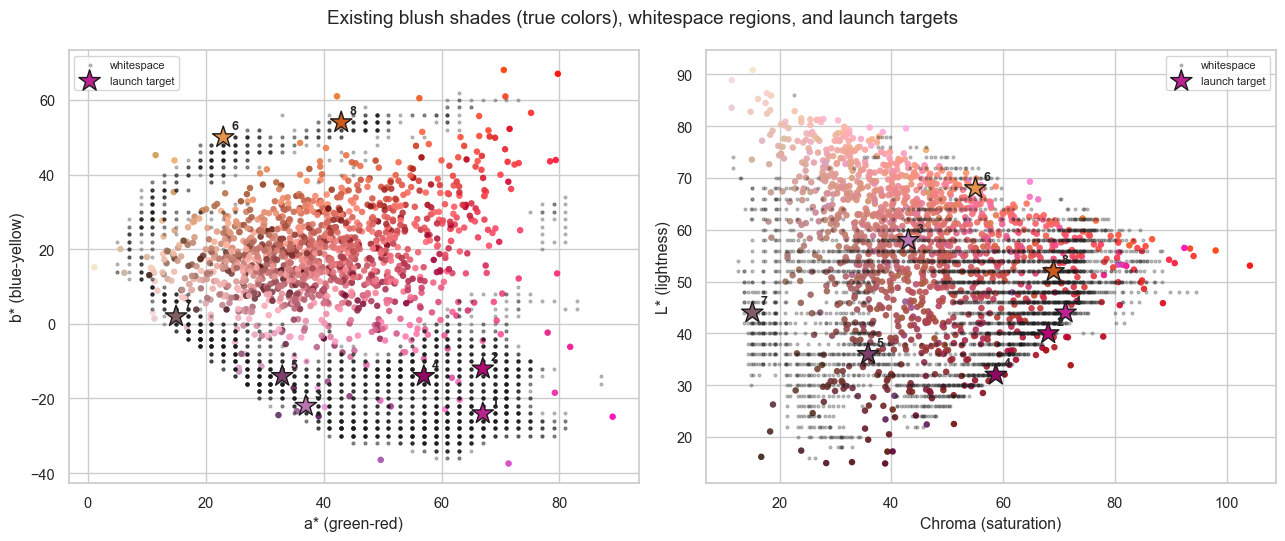

In [8]:
from sklearn.cluster import KMeans
K_GAP = min(8, max(1, len(gaps)//3))
km = KMeans(K_GAP, n_init=10, random_state=0).fit(gaps, sample_weight=gap_d)
rows = []
for c in range(K_GAP):
    m = km.labels_ == c
    pts, d = gaps[m], gap_d[m]
    best = pts[d.argmax()]                      # the emptiest point in this region = target shade
    nn_d, nn_i = tree_all.query(best, k=5)
    rows.append(dict(opportunity=c+1, target_hex=lab_to_hex(best[None])[0], L=best[0], a=best[1], b=best[2],
                     C=np.hypot(best[1], best[2]), h=np.degrees(np.arctan2(best[2], best[1])) % 360,
                     gap_size_de=d.max(), region_points=m.sum(),
                     nearest_existing=df.hex.iloc[nn_i[0]], nearest_brand=df.brand.iloc[nn_i[0]],
                     likely_season=df.season.iloc[nn_i].mode().iloc[0]))
whitespace = pd.DataFrame(rows).sort_values("region_points", ascending=False).reset_index(drop=True)
whitespace["opportunity"] = whitespace.index + 1
display(whitespace.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (xk, yk, xl, yl) in zip(axes, [("a","b","a* (green-red)","b* (blue-yellow)"), ("C","L","Chroma (saturation)","L* (lightness)")]):
    ax.scatter(df[xk], df[yk], c=df.hex, s=22, edgecolor="none", alpha=0.9)
    gx = gaps[:,1] if xk=="a" else np.hypot(gaps[:,1], gaps[:,2]); gy = gaps[:,2] if yk=="b" else gaps[:,0]
    ax.scatter(gx, gy, c="k", s=4, alpha=0.25, label="whitespace")
    ox = whitespace.a if xk=="a" else whitespace.C; oy = whitespace.b if yk=="b" else whitespace.L
    ax.scatter(ox, oy, c=whitespace.target_hex, s=260, marker="*", edgecolor="k", lw=1, label="launch target")
    for i, r in whitespace.iterrows(): ax.annotate(int(r.opportunity), ((r.a if xk=="a" else r.C), (r.b if yk=="b" else r.L)), xytext=(6,6), textcoords="offset points", fontsize=9, fontweight="bold")
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(loc="best", fontsize=8)
fig.suptitle("Existing blush shades (true colors), whitespace regions, and launch targets"); plt.tight_layout(); plt.show()

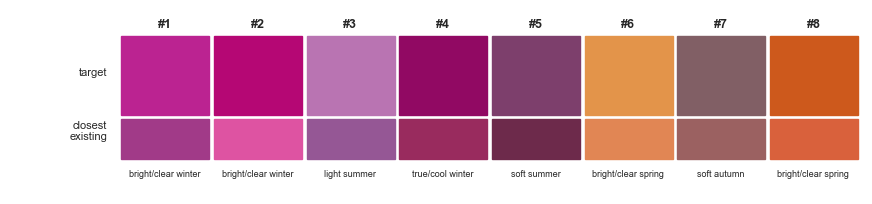

In [9]:
# Swatch strip of the recommended gap-filling shades next to their nearest existing shade
fig, ax = plt.subplots(figsize=(11, 2.4)); ax.axis("off")
for i, r in whitespace.iterrows():
    ax.add_patch(plt.Rectangle((i, 0.5), 0.95, 0.9, color=r.target_hex)); ax.add_patch(plt.Rectangle((i, 0), 0.95, 0.45, color=r.nearest_existing))
    ax.text(i+0.47, 1.5, f"#{int(r.opportunity)}", ha="center", fontsize=9, fontweight="bold")
    ax.text(i+0.47, -0.2, r.likely_season, ha="center", fontsize=6.5)
ax.text(-0.15, 0.95, "target", ha="right", fontsize=8); ax.text(-0.15, 0.22, "closest\nexisting", ha="right", fontsize=8)
ax.set_xlim(-1.2, len(whitespace)); ax.set_ylim(-0.4, 1.7); plt.show()

## 2. How redundant are shades within a brand?
A shade is **redundant** if another shade in the same brand is within `DE_DUP` ΔE of it (customers can't tell them apart on the pan). Redundancy rate = share of a brand's shades that are redundant. Those are SKU-rationalization candidates.

Market-wide: 26% of shades in analyzed brands have a near-twin in the same brand


,brand,n_shades,redundancy_rate,median_nn_de,exact_hex_dupes
0,KIKO Milano,17,0.59,4.71,0
1,Laura Mercier,19,0.47,6.29,0
2,bareMinerals,34,0.44,5.99,0
3,Benefit Cosmetics,25,0.44,6.62,0
4,Tarte,54,0.43,5.42,0
5,NARS,26,0.42,6.42,0
6,J.Cat Beauty,17,0.41,7.23,0
7,MAC,49,0.41,5.67,1
8,Maybelline,18,0.39,5.38,0
9,Revolution Beauty,40,0.38,6.41,0


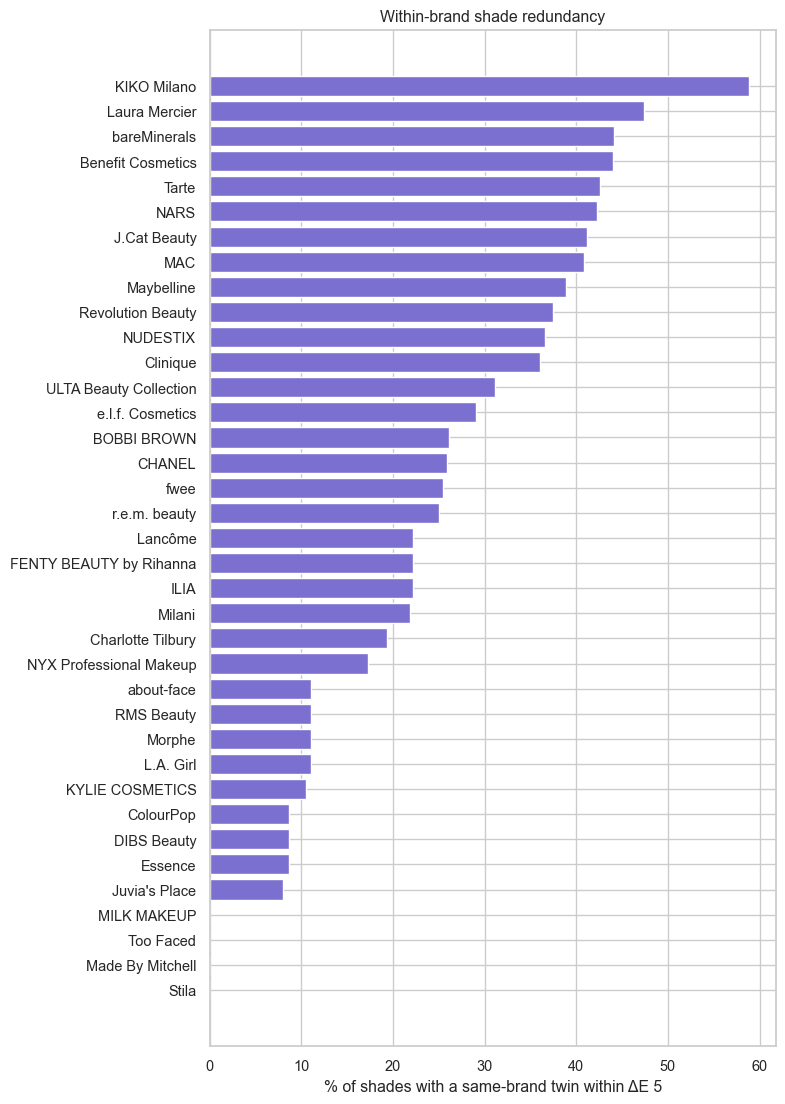

In [10]:
red_rows, pair_rows = [], []
for brand in brands_ok:
    g = df[df.brand == brand].reset_index(drop=True); P = g[["L","a","b"]].values
    d, i = cKDTree(P).query(P, k=2)               # k=2 -> nearest OTHER shade
    nn = d[:, 1]
    red_rows.append(dict(brand=brand, n_shades=len(g), redundancy_rate=(nn < DE_DUP).mean(),
                         median_nn_de=np.median(nn), exact_hex_dupes=len(g) - g.hex.nunique()))
    for a_i in np.where(nn < DE_DUP)[0]:
        b_i = i[a_i, 1]
        if a_i < b_i or nn[b_i] >= DE_DUP or i[b_i,1] != a_i:
            pair_rows.append(dict(brand=brand, shade_a=g.swatch_alt[a_i], shade_b=g.swatch_alt[b_i], hex_a=g.hex[a_i], hex_b=g.hex[b_i], delta_e=nn[a_i], same_product=g["product"][a_i]==g["product"][b_i]))
redundancy = pd.DataFrame(red_rows).sort_values("redundancy_rate", ascending=False).reset_index(drop=True)
pairs_red = pd.DataFrame(pair_rows).drop_duplicates(["brand","hex_a","hex_b"]).sort_values("delta_e")
print(f"Market-wide: {np.average(redundancy.redundancy_rate, weights=redundancy.n_shades):.0%} of shades in analyzed brands have a near-twin in the same brand")
display(redundancy.round(2).head(12))

fig, ax = plt.subplots(figsize=(8, 0.27*len(redundancy)+1.2)); r = redundancy.sort_values("redundancy_rate")
ax.barh(r.brand, r.redundancy_rate*100, color="#7b6fd0"); ax.set_xlabel(f"% of shades with a same-brand twin within ΔE {DE_DUP}")
ax.set_title("Within-brand shade redundancy"); plt.tight_layout(); plt.show()

Closest same-brand shade pairs (cut or merge candidates):


,brand,shade_a,shade_b,hex_a,hex_b,delta_e,same_product
32,NUDESTIX,Pulse Gel Color Lip + Cheek Balm,Pixi Intense Matte Lip + Cheek Pencil,#b46c6f,#b46c6f,0.00,False
37,MAC,Light Effervescence Extra Dimension Face Compa...,Light Effervescence Extra Dimension Face Compact,#deaca5,#deaca5,0.00,True
77,Charlotte Tilbury,Pillow Talk Flawless Peach Pillow Talk Beauty ...,Pillow Talk Flawless Peach Pillow Talk Beauty ...,#ca6460,#ca6460,0.00,True
86,CHANEL,1 RED CAMELLIA N°1 DE CHANEL Lip and Cheek Balm,6 BERRY BOOST N°1 DE CHANEL Lip and Cheek Balm,#aa1b1a,#aa1b1a,0.00,True
73,Milani,Bellissimo Bronze Baked Blush - Radiant Powder...,Rose D'oro Baked Blush - Radiant Powder Blush,#e3977a,#e39779,0.53,True
103,Benefit Cosmetics,Benetint Benetint Liquid Lip & Cheek Stain,Rose-tinted Value Size Liquid Lip Blush & Chee...,#bb022d,#bb032e,0.56,False
106,Benefit Cosmetics,Shellie Silky-Soft Powder Blush,Sunny Silky-Soft Powder Blush,#f79381,#f5917f,0.73,True
104,Benefit Cosmetics,Dandelion Silky-Soft Powder Blush,Dandelion WANDERful World Silky-Soft Powder Bl...,#f2a39d,#f1a19c,0.86,False
29,NUDESTIX,Sunkissed Pink Intense Matte Lip + Cheek Pencil,Cheeky Coral STAX All Over Color Blush Balm,#c7716a,#c46f69,1.09,False
64,bareMinerals,Kiss of Pink COMPLEXION RESCUE Liquid Blonzer ...,Kiss of Copper GEN NUDE BLONZER Blush + Bronzer,#d98e80,#dc8e81,1.33,False


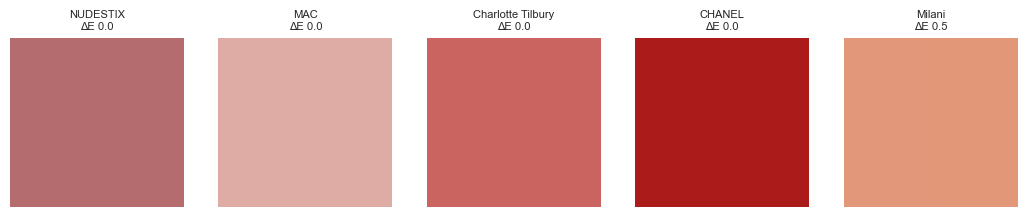

In [11]:
print("Closest same-brand shade pairs (cut or merge candidates):")
display(pairs_red.head(10).round(2))
fig, axes = plt.subplots(1, 5, figsize=(13, 2.2))
for ax, (_, r) in zip(axes, pairs_red.head(5).iterrows()):
    ax.add_patch(plt.Rectangle((0,0), 1, 1, color=r.hex_a)); ax.add_patch(plt.Rectangle((1,0), 1, 1, color=r.hex_b))
    ax.set_xlim(0,2); ax.set_ylim(0,1); ax.axis("off"); ax.set_title(f"{r.brand}\nΔE {r.delta_e:.1f}", fontsize=8)
plt.show()

## 3. Which brands have a wide or narrow hue range per product line?
For each product line (one `product`) with at least 4 shades, measure:
- **Hue range** = the smallest arc of the hue circle containing all shades (circular, so 350° and 10° are 20° apart). Only shades with chroma ≥ 8 are used because hue is unstable for near-neutrals.
- **Lightness range** (L* max - min) and **palette spread** = average pairwise ΔE within the product.

In [12]:
def circ_range(h):
    h = np.sort(np.asarray(h) % 360)
    if len(h) < 2: return 0.0
    gaps = np.diff(np.r_[h, h[0] + 360])
    return 360 - gaps.max()

prod_rows = []
for (brand, product), g in df.groupby(["brand","product"]):
    if len(g) < 4: continue
    P = g[["L","a","b"]].values
    spread = np.linalg.norm(P[:, None] - P[None], axis=-1)[np.triu_indices(len(g), 1)].mean()
    chroma_ok = g[g.C >= 8]
    prod_rows.append(dict(brand=brand, product=product, n_shades=len(g), hue_range_deg=circ_range(chroma_ok.h) if len(chroma_ok) >= 2 else np.nan,
                          lightness_range=g.L.max() - g.L.min(), palette_spread_de=spread))
prod_range = pd.DataFrame(prod_rows)
print(f"{len(prod_range)} product lines with >= 4 shades")
print("Widest product-line palettes (by hue range):"); display(prod_range.sort_values("hue_range_deg", ascending=False).head(8).round(1))
print("Narrowest:"); display(prod_range.sort_values("hue_range_deg").head(8).round(1))

161 product lines with >= 4 shades
Widest product-line palettes (by hue range):


,brand,product,n_shades,hue_range_deg,lightness_range,palette_spread_de
100,NUDESTIX,STAX All Over Color Blush Balm,12,92.7,32.4,28.3
79,Made By Mitchell,Blursh Pod Domed Blusher,6,76.3,29.9,30.2
74,MAC,Strobe Beam Liquid Blush,10,76.0,56.0,38.4
63,LORAC,Color Source Buildable Blush,9,74.5,44.5,23.9
37,HALF MAGIC,Cheek Fluff Soft Blur Cream Blush,5,73.5,42.6,44.3
35,FENTY BEAUTY by Rihanna,Fenty Cheeks Suede Waterproof Powder Blush,8,73.3,37.2,33.6
96,NUDESTIX,NUDIES MATTE All Over Face Blush Color,9,73.3,45.1,32.3
143,about-face,Cheek Freak Blush Balm,10,73.2,33.2,30.6


Narrowest:


,brand,product,n_shades,hue_range_deg,lightness_range,palette_spread_de
149,bareMinerals,Talc Free Loose Mineral Blush,4,7.6,13.2,10.2
87,Milani,Rose Powder Blush,4,7.7,1.9,14.9
132,ULTA Beauty Collection,Cheek Squad Cream Face Trio,4,8.7,36.5,22.3
68,Live Tinted,Blush Crush Liquid Blush,5,10.6,33.3,18.9
123,Stila,Complete Harmony Lip & Cheek Stick,4,10.7,29.3,25.7
16,Clinique,Blushing Blush Powder Blush,5,12.0,8.3,7.4
124,Stila,Convertible Color Lip & Cheek Cream Blush,4,12.2,10.9,17.4
140,Winky Lux,Cheeky Rose Cream Blush,4,12.4,11.8,17.4


,product_lines,median_hue_range,median_lightness_range,median_spread,range_class
brand,,,,,
about-face,2,68.6,36.3,33.1,Wide
Made By Mitchell,3,68.4,34.2,39.6,Wide
NARS,2,56.4,37.5,25.9,Wide
Persona,2,53.4,27.8,30.1,Wide
FENTY BEAUTY by Rihanna,2,53.4,48.7,32.9,Wide
fwee,2,51.9,49.3,25.3,Wide
NYX Professional Makeup,3,51.7,24.0,29.0,Wide
MAC,5,49.8,14.9,21.6,Wide
r.e.m. beauty,2,47.6,23.7,26.2,Wide


...


,product_lines,median_hue_range,median_lightness_range,median_spread,range_class
brand,,,,,
Benefit Cosmetics,3,18.7,34.5,23.3,Narrow
KIKO Milano,3,18.1,12.4,12.8,Narrow
L'Oréal,2,17.3,26.0,21.4,Narrow
Live Tinted,2,15.9,34.8,20.5,Narrow
Clinique,3,15.1,13.0,15.8,Narrow
Stila,3,12.2,29.3,25.7,Narrow


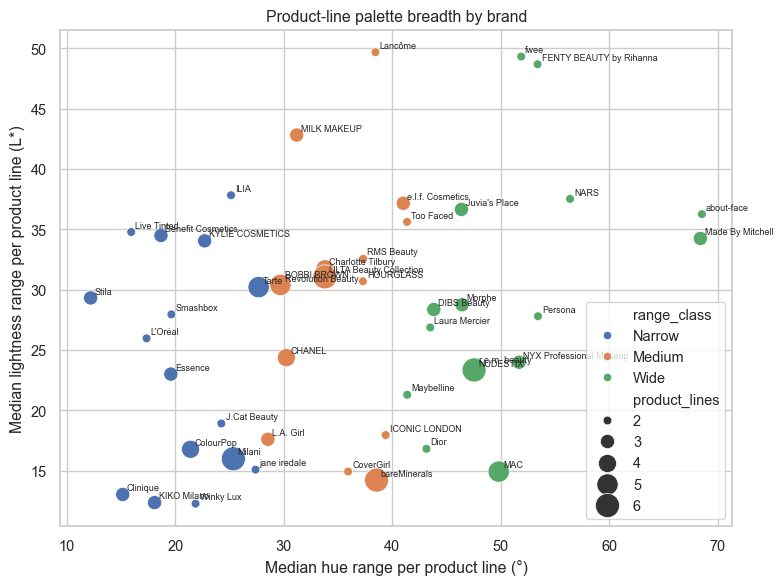

In [16]:
brand_range = (prod_range.groupby("brand").agg(product_lines=("product","count"), median_hue_range=("hue_range_deg","median"),
               median_lightness_range=("lightness_range","median"), median_spread=("palette_spread_de","median"))
               .query("product_lines >= 2").sort_values("median_hue_range", ascending=False))
brand_range["range_class"] = pd.qcut(brand_range.median_hue_range.rank(method="first"), 3, labels=["Narrow","Medium","Wide"])
display(brand_range.round(1).head(10)); print("..."); display(brand_range.round(1).tail(6))
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=brand_range.reset_index(), x="median_hue_range", y="median_lightness_range", size="product_lines", hue="range_class", sizes=(40, 300), ax=ax)
for b, r in brand_range.iterrows(): ax.annotate(b, (r.median_hue_range, r.median_lightness_range), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Median hue range per product line (°)"); ax.set_ylabel("Median lightness range per product line (L*)")
ax.set_title("Product-line palette breadth by brand"); plt.tight_layout(); plt.show()

## 4. What should a new brand launch with?
**Problem:** choose *k* shades so as many existing market shades as possible have a launch shade within `DE_COVER` ΔE (a maximum-coverage / set-cover problem, solved greedily, which is guaranteed to be within about 63% of optimal).
Two scenarios:
- **Market-weighted:** every existing shade counts equally. This mirrors what is on shelves and over-serves spring.
- **Season-balanced:** shades are weighted by the inverse of their season's frequency, so scarce seasons count more.

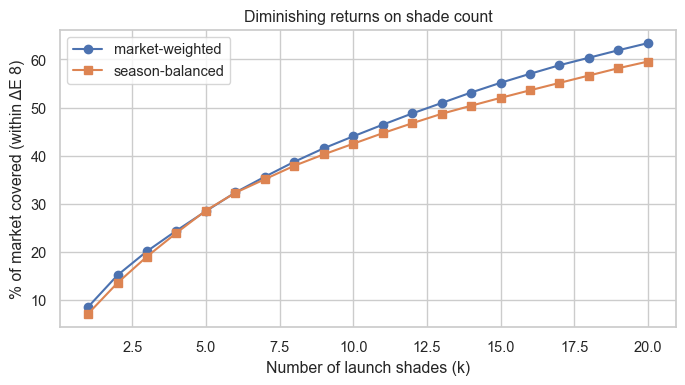

 k  market_weighted_coverage  season_balanced_coverage
 6                     0.323                     0.323
 8                     0.387                     0.379
10                     0.440                     0.425
12                     0.488                     0.467
16                     0.570                     0.536
20                     0.634                     0.595


In [13]:
nbrs = tree_all.query_ball_point(X, r=DE_COVER)       # shades each candidate shade could cover
def greedy_cover(weights, k):
    covered = np.zeros(len(X), bool); picks, curve = [], []
    for _ in range(k):
        gains = np.array([weights[[j for j in nb if not covered[j]]].sum() for nb in nbrs])
        j = gains.argmax(); picks.append(j); covered[nbrs[j]] = True; curve.append(weights[covered].sum() / weights.sum())
    return picks, curve

w_market = np.ones(len(X))
season_freq = df.season.map(df.season.value_counts()).values.astype(float)
w_bal = 1 / season_freq
K = 20
picks_m, curve_m = greedy_cover(w_market, K); picks_b, curve_b = greedy_cover(w_bal, K)
curve = pd.DataFrame({"k": range(1, K+1), "market_weighted_coverage": curve_m, "season_balanced_coverage": curve_b})
fig, ax = plt.subplots(figsize=(7, 4)); ax.plot(curve.k, curve.market_weighted_coverage*100, marker="o", label="market-weighted")
ax.plot(curve.k, curve.season_balanced_coverage*100, marker="s", label="season-balanced"); ax.set_xlabel("Number of launch shades (k)"); ax.set_ylabel(f"% of market covered (within ΔE {DE_COVER})")
ax.set_title("Diminishing returns on shade count"); ax.legend(); plt.tight_layout(); plt.show()
print(curve.query("k in [6, 8, 10, 12, 16, 20]").round(3).to_string(index=False))

,scenario,launch_rank,hex,season,family,L,a,b,C,h,market_shades_covered
0,market-weighted,1,#d6736c,light spring,spring,59.6,38.0,21.4,43.5,29.4,110
1,market-weighted,2,#e1968f,light spring,spring,69.3,27.3,15.3,31.3,29.2,85
2,market-weighted,3,#bc6469,true/warm autumn,autumn,52.8,35.7,13.2,38.1,20.3,79
3,market-weighted,4,#eb838a,light spring,spring,66.3,40.5,14.0,42.9,19.1,76
4,market-weighted,5,#ec816c,light spring,spring,65.5,39.0,29.7,49.1,37.2,67
5,market-weighted,6,#e76268,light spring,spring,58.7,52.1,22.9,56.9,23.8,54
6,market-weighted,7,#be5058,true/warm autumn,autumn,48.8,44.9,17.9,48.3,21.7,53
7,market-weighted,8,#c27869,light spring,spring,58.0,27.3,20.5,34.1,36.9,65
8,market-weighted,9,#a1534e,true/warm autumn,autumn,44.7,31.6,17.6,36.2,29.1,48
9,market-weighted,10,#ed9881,light spring,spring,70.9,29.4,25.4,38.8,40.8,50


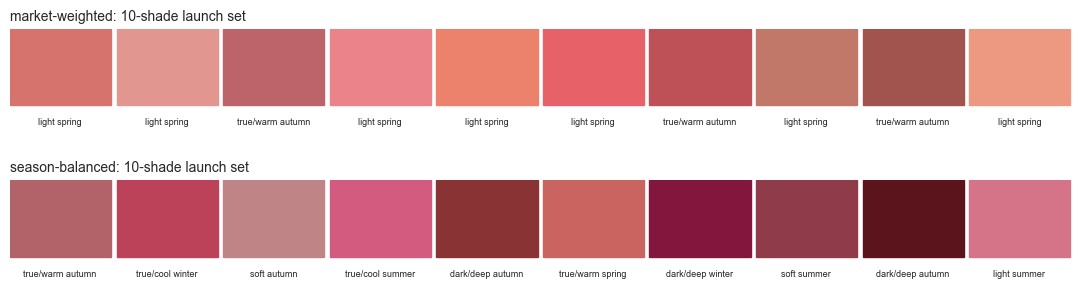

market-weighted  season families in the 10-shade set: {'spring': 7, 'summer': 0, 'autumn': 3, 'winter': 0}
season-balanced  season families in the 10-shade set: {'spring': 1, 'summer': 3, 'autumn': 4, 'winter': 2}


In [18]:
K_LAUNCH = 10
def launch_table(picks, tag):
    t = df.iloc[picks[:K_LAUNCH]][["hex","season","family","L","a","b","C","h"]].copy()
    t.insert(0, "scenario", tag); t.insert(1, "launch_rank", range(1, K_LAUNCH+1)); t["market_shades_covered"] = [len(nbrs[j]) for j in picks[:K_LAUNCH]]
    return t.reset_index(drop=True)
launch = pd.concat([launch_table(picks_m, "market-weighted"), launch_table(picks_b, "season-balanced")])
display(launch.round(1))

fig, axes = plt.subplots(2, 1, figsize=(11, 3.2))
for ax, (tag, g) in zip(axes, launch.groupby("scenario", sort=False)):
    for i, (_, r) in enumerate(g.iterrows()):
        ax.add_patch(plt.Rectangle((i, 0), 0.95, 1, color=r.hex)); ax.text(i+0.47, -0.25, r.season, ha="center", fontsize=6.5)
    ax.set_xlim(0, K_LAUNCH); ax.set_ylim(-0.5, 1); ax.axis("off"); ax.set_title(f"{tag}: {K_LAUNCH}-shade launch set", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

for tag, picks in [("market-weighted", picks_m), ("season-balanced", picks_b)]:
    fam_cov = df.iloc[picks[:K_LAUNCH]].family.value_counts().reindex(["spring","summer","autumn","winter"], fill_value=0)
    print(f"{tag:16s} season families in the {K_LAUNCH}-shade set:", fam_cov.to_dict())

**Reading it:** the market-weighted set is the safe, shelf-matching launch; the season-balanced set is the differentiated, inclusive launch. Combine with the whitespace targets from section 1 to add one or two truly new shades.

## 5. Which brands compete head to head?
**Overlap(A→B)** = share of A's shades that have a B shade within `DE_RIVAL` ΔE (a customer could substitute it). Because brands differ in size, **rivalry** = geometric mean of the two directions (A→B and B→A).

In [14]:
Pm = {b: df.loc[df.brand==b, ["L","a","b"]].values for b in brands_ok}; Tm = {b: cKDTree(Pm[b]) for b in brands_ok}
O = pd.DataFrame(0.0, index=brands_ok, columns=brands_ok)
for A in brands_ok:
    for B in brands_ok:
        if A != B: O.loc[A, B] = (Tm[B].query(Pm[A])[0] <= DE_RIVAL).mean()
R = np.sqrt(O * O.T)                                   # symmetric rivalry score
rival_pairs = pd.DataFrame([(a, b, R.loc[a, b], O.loc[a, b], O.loc[b, a]) for i, a in enumerate(brands_ok) for b in brands_ok[i+1:]],
                           columns=["brand_a","brand_b","rivalry","a_to_b_overlap","b_to_a_overlap"]).sort_values("rivalry", ascending=False)
print("Closest head-to-head rivals:"); display(rival_pairs.head(12).round(2))
top_rivals = (R.apply(lambda r: ", ".join(r.drop(r.name).nlargest(3).index), axis=1)).rename("top_3_rivals")
display(pd.concat([R.mean(axis=1).rename("avg_rivalry"), top_rivals], axis=1).sort_values("avg_rivalry", ascending=False).round(2).head(12))

Closest head-to-head rivals:


,brand_a,brand_b,rivalry,a_to_b_overlap,b_to_a_overlap
101,NUDESTIX,KIKO Milano,0.61,0.42,0.88
509,ColourPop,KIKO Milano,0.58,0.43,0.76
90,NUDESTIX,Laura Mercier,0.57,0.44,0.74
85,NUDESTIX,BOBBI BROWN,0.55,0.44,0.70
86,NUDESTIX,ColourPop,0.52,0.44,0.61
151,ULTA Beauty Collection,ColourPop,0.51,0.40,0.65
51,Tarte,BOBBI BROWN,0.51,0.43,0.61
655,RMS Beauty,Stila,0.51,0.56,0.47
20,fwee,KYLIE COSMETICS,0.50,0.35,0.74
0,fwee,Tarte,0.50,0.47,0.54


,avg_rivalry,top_3_rivals
Tarte,0.35,"BOBBI BROWN, fwee, Laura Mercier"
NUDESTIX,0.32,"KIKO Milano, Laura Mercier, BOBBI BROWN"
ColourPop,0.31,"KIKO Milano, NUDESTIX, ULTA Beauty Collection"
e.l.f. Cosmetics,0.30,"ULTA Beauty Collection, ILIA, RMS Beauty"
fwee,0.29,"KYLIE COSMETICS, Tarte, Clinique"
ULTA Beauty Collection,0.29,"ColourPop, bareMinerals, e.l.f. Cosmetics"
Clinique,0.29,"bareMinerals, Tarte, ULTA Beauty Collection"
Charlotte Tilbury,0.29,"bareMinerals, Tarte, RMS Beauty"
bareMinerals,0.28,"ULTA Beauty Collection, Charlotte Tilbury, Cli..."
Revolution Beauty,0.28,"Clinique, e.l.f. Cosmetics, NARS"


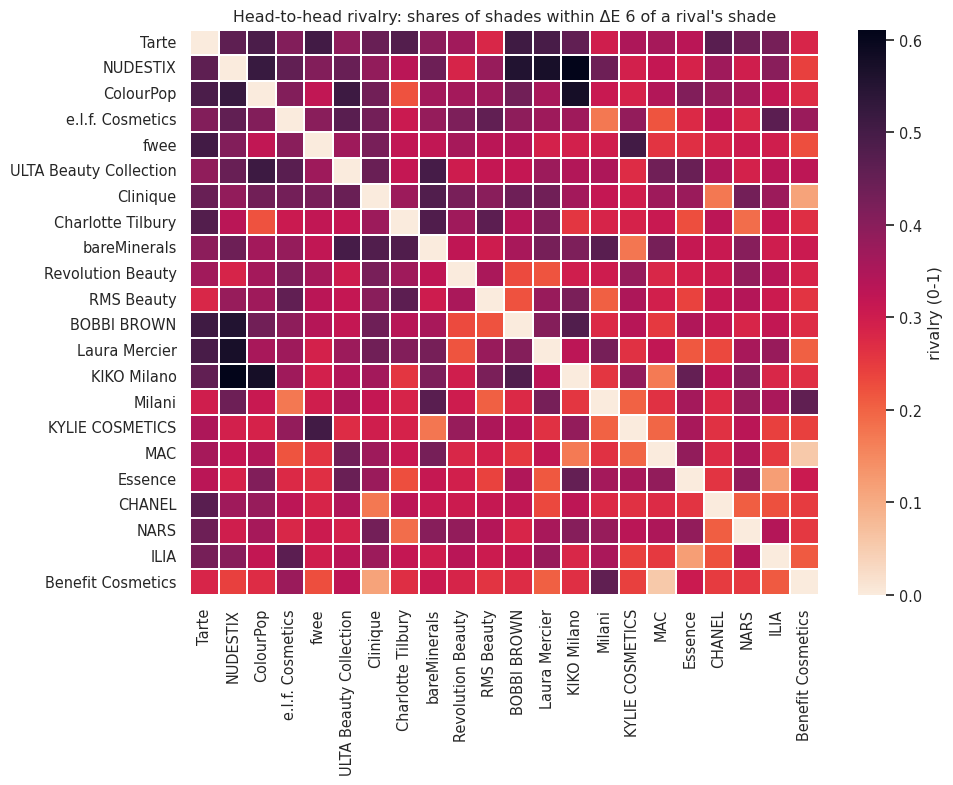

ΔE <= 4: top pairs -> KIKO Milano / NUDESTIX; Charlotte Tilbury / L.A. Girl; ULTA Beauty Collection / bareMinerals
ΔE <= 6: top pairs -> KIKO Milano / NUDESTIX; ColourPop / KIKO Milano; Laura Mercier / NUDESTIX
ΔE <= 8: top pairs -> ColourPop / NUDESTIX; ColourPop / KIKO Milano; BOBBI BROWN / NUDESTIX


In [15]:
order = R.mean(axis=1).sort_values(ascending=False).head(22).index
fig, ax = plt.subplots(figsize=(10, 8)); sns.heatmap(R.loc[order, order], cmap="rocket_r", annot=False, linewidths=0.2, cbar_kws={"label":"rivalry (0-1)"}, ax=ax)
ax.set_title(f"Head-to-head rivalry: shares of shades within ΔE {DE_RIVAL} of a rival's shade"); plt.tight_layout(); plt.show()

# Sensitivity: do the top rivals depend on the threshold?
for t in [4, 6, 8]:
    Rt = pd.DataFrame({A: {B: np.sqrt((Tm[B].query(Pm[A])[0] <= t).mean() * (Tm[A].query(Pm[B])[0] <= t).mean()) for B in brands_ok if B != A} for A in brands_ok})
    s = Rt.stack().reset_index(); s.columns = ["a","b","r"]; s = s[s.a < s.b].nlargest(3, "r")
    print(f"ΔE <= {t}: top pairs ->", "; ".join(f"{x.a} / {x.b}" for x in s.itertuples()))

## 6. Export for Tableau

In [19]:
df[["brand","product","swatch_alt","hex","season","family","L","a","b","C","h"]].to_csv("tableau_exports/shades_lab.csv", index=False)
whitespace.to_csv("tableau_exports/whitespace_opportunities.csv", index=False)
pd.DataFrame(gaps, columns=["L","a","b"]).assign(gap_de=gap_d, hex=lab_to_hex(gaps)).to_csv("tableau_exports/whitespace_points.csv", index=False)
redundancy.to_csv("tableau_exports/brand_redundancy.csv", index=False); pairs_red.to_csv("tableau_exports/redundant_pairs.csv", index=False)
prod_range.to_csv("tableau_exports/product_line_range.csv", index=False); brand_range.reset_index().to_csv("tableau_exports/brand_hue_range.csv", index=False)
curve.to_csv("tableau_exports/launch_coverage_curve.csv", index=False); launch.to_csv("tableau_exports/launch_sets.csv", index=False)
R.stack().rename("rivalry").rename_axis(["brand_a","brand_b"]).reset_index().to_csv("tableau_exports/brand_rivalry.csv", index=False)
print(sorted(os.listdir("tableau_exports")))

['.ipynb_checkpoints', 'brand_hue_range.csv', 'brand_palette_distance.csv', 'brand_redundancy.csv', 'brand_rivalry.csv', 'brand_scorecard.csv', 'brand_season_coverage.csv', 'launch_coverage_curve.csv', 'launch_sets.csv', 'product_line_range.csv', 'redundant_pairs.csv', 'shades_lab.csv', 'whitespace_opportunities.csv', 'whitespace_points.csv']


## 7. Findings summary (fill in with your final numbers)
- **Whitespace:** 3,222 grid points in the market’s color space sit at least 8 ΔE from every existing shade. I grouped them into 8 launch opportunities.  
Five of the 8 are deep, saturated magenta, berry and plum shades (high chroma, cool hues), and the rest are scattered: one warm orange, one orange-tan and one muted rosy-brown. The orange-tan and orange shades are labeled bright/clear spring.  
The biggest empty region is #bb2391 (721 grid points). The single largest gap is  #b50774, at 17.4 ΔE from the nearest existing shade.  
- **Redundancy:** 26% of shades (258 of 976, across the 37 brands analyzed) have a near-twin in the same brand, within ΔE 5. KIKO Milano is highest at 59%, which is 10 of its 17 shades. bareMinerals has the most absolute duplicates, 15 of 34.  
- **Range:** About-face has the widest product-line hue range (median 69°), and Stila has the narrowest (12°). This covers 47 brands with at least 2 product lines of 4 or more shades each.  
- **Launch:** A 10-shade set covers 44% of the market’s shades (within ΔE 8) when weighted by the market, and 42.5% when balanced across seasons.  
Coverage does not flatten by 20 shades: it keeps climbing to 63% (market-weighted) and 60% (balanced).
Returns do diminish, though. The first shade adds 8.6 percentage points, the tenth adds 2.5, and the twentieth adds 1.5.  
The market-weighted set is 7 spring and 3 autumn shades, with no summer or winter. The balanced set spans all four families.  
- **Competition:** NUDESTIX, KIKO Milano and ColourPop are the closest rivals. NUDESTIX and KIKO Milano are the top pair at ΔE thresholds of 4 and 6, and ColourPop and NUDESTIX lead at 8.  
The exact top pair isn’t stable across thresholds, so I changed your line. What is stable is that these three brands show up in the top pairs.  